In [1]:
import pandas as pd
print("Setup complete!")

Setup complete!


In [3]:
df = pd.read_csv('01-population-by-self-governed-unit.csv', skiprows=3)
df.head()

,"regions, self-governed units",1994,1995,1996,1997,1998,1999,2000,2001,2002,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
0,Georgia,"4,929.9","4,742.3","4,573.2","4,410.2","4,289.6","4,197.6","4,116.8","4,037.5","3,991.3",...,"3,726.4","3,729.6","3,723.5","3,716.9","3,728.6","3,688.6","3,736.4","3,694.6","3,930.4","3,941.1"
1,C. Tbilisi Municipality,"1,250.7","1,205.3","1,164.4","1,131.4","1,103.1","1,085.2","1,072.8","1,062.2","1,062.2",...,"1,145.5","1,158.7","1,171.1","1,184.8","1,202.7","1,201.8","1,241.7","1,258.5","1,335.7","1,369.4"
2,Abkhazia A.R.,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.6,...,-,-,-,-,-,-,-,-,-,-
3,Ajara Municipality,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.6,...,-,-,-,-,-,-,-,-,-,-
4,Adjara A.R.,423.0,411.0,391.6,374.0,366.3,360.0,353.0,347.4,342.1,...,343.0,346.3,349.0,351.9,354.9,355.5,361.4,363.2,404.1,413.2


In [4]:
df.shape
df.columns

Index(['regions, self-governed units', '1994', '1995', '1996', '1997', '1998',
       '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007',
       '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016',
       '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025',
       '2026'],
      dtype='object')

In [5]:
print(df.shape)

(93, 34)


In [6]:
# Check data types
df.dtypes


regions, self-governed units    object
1994                            object
1995                            object
1996                            object
1997                            object
1998                            object
1999                            object
2000                            object
2001                            object
2002                            object
2003                            object
2004                            object
2005                            object
2006                            object
2007                            object
2008                            object
2009                            object
2010                            object
2011                            object
2012                            object
2013                            object
2014                            object
2015                            object
2016                            object
2017                            object
2018                     

In [7]:
# List of year columns
years = [str(y) for y in range(1994, 2027)]

# Clean: remove commas, replace "-" with NaN, convert to float
for col in years:
    df[col] = df[col].astype(str).str.replace(',', '', regex=False)
    df[col] = df[col].replace('-', pd.NA)
    df[col] = pd.to_numeric(df[col], errors='coerce')

df.dtypes

regions, self-governed units     object
1994                            float64
1995                            float64
1996                            float64
1997                            float64
1998                            float64
1999                            float64
2000                            float64
2001                            float64
2002                            float64
2003                            float64
2004                            float64
2005                            float64
2006                            float64
2007                            float64
2008                            float64
2009                            float64
2010                            float64
2011                            float64
2012                            float64
2013                            float64
2014                            float64
2015                            float64
2016                            float64
2017                            float64


In [8]:
# Filter for Tbilisi
tbilisi = df[df['regions, self-governed units'] == 'C. Tbilisi Municipality']
tbilisi[years]


,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
1,1250.7,1205.3,1164.4,1131.4,1103.1,1085.2,1072.8,1062.2,1062.2,1062.8,...,1145.5,1158.7,1171.1,1184.8,1202.7,1201.8,1241.7,1258.5,1335.7,1369.4


Matplotlib is building the font cache; this may take a moment.


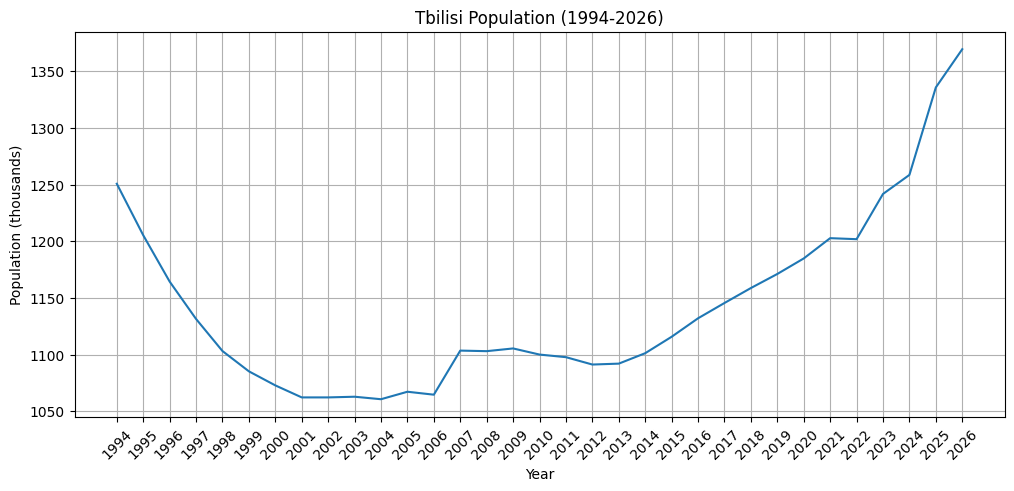

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(years, tbilisi[years].values[0])
plt.title('Tbilisi Population (1994-2026)')
plt.xlabel('Year')
plt.ylabel('Population (thousands)')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [10]:
# Get top 5 regions by 2026 population
top5 = df.nlargest(6, '2026')[['regions, self-governed units', '2026']]
top5

,"regions, self-governed units",2026
0,Georgia,3941.1
1,C. Tbilisi Municipality,1369.4
16,Imereti,492.5
71,Kvemo Kartli,440.1
4,Adjara A.R.,413.2
29,Kakheti,300.0


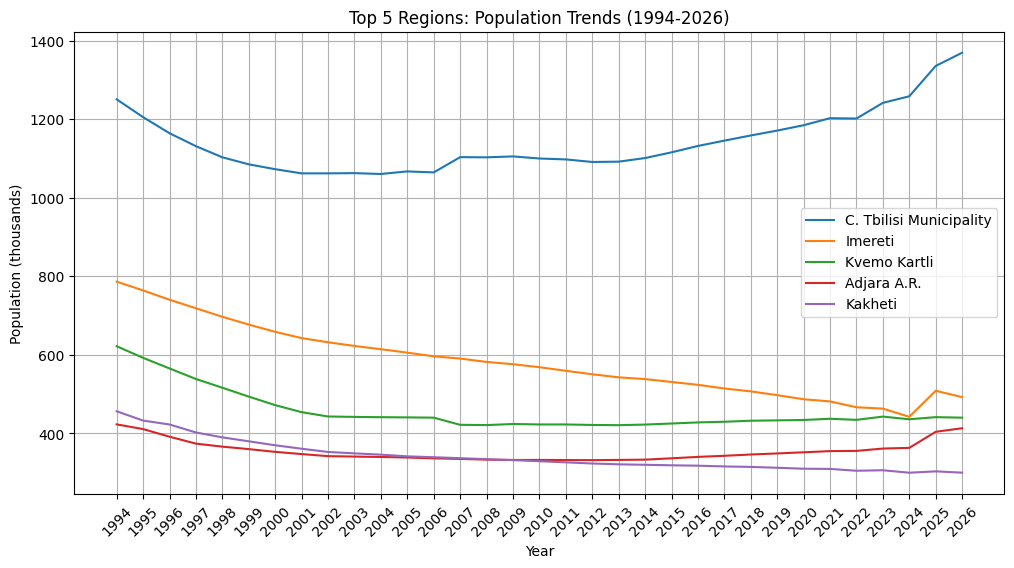

In [11]:
# Filter out "Georgia" (total), keep top 5 regions
top_regions = df[df['regions, self-governed units'] != 'Georgia'].nlargest(5, '2026')

plt.figure(figsize=(12, 6))
for idx, row in top_regions.iterrows():
    plt.plot(years, row[years].values, label=row['regions, self-governed units'])

plt.title('Top 5 Regions: Population Trends (1994-2026)')
plt.xlabel('Year')
plt.ylabel('Population (thousands)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.show()

In [12]:
# Calculate % change from 1994 to 2026
df['change_pct'] = ((df['2026'] - df['1994']) / df['1994']) * 100

# Exclude "Georgia" total row
regions_only = df[df['regions, self-governed units'] != 'Georgia']

# Top 5 growing
print("TOP 5 GROWING:")
print(regions_only.nlargest(5, 'change_pct')[['regions, self-governed units', '1994', '2026', 'change_pct']])

print("\nTOP 5 DECLINING:")
print(regions_only.nsmallest(5, 'change_pct')[['regions, self-governed units', '1994', '2026', 'change_pct']])

TOP 5 GROWING:
   regions, self-governed units    1994    2026  change_pct
5        C. Batumi Municipality   147.3   246.3   67.209776
1       C. Tbilisi Municipality  1250.7  1369.4    9.490685
4                   Adjara A.R.   423.0   413.2   -2.316785
77        Marneuli Municipality   128.3   116.7   -9.041309
36        Sagarejo Municipality    62.7    50.9  -18.819777

TOP 5 DECLINING:
   regions, self-governed units  1994  2026  change_pct
78          Tsalka Municipality  49.0  17.8  -63.673469
50             Oni Municipality  15.0   5.6  -62.666667
24         Tqibuli Municipality  39.0  16.9  -56.666667
10           Khulo Municipality  36.8  16.1  -56.250000
51         Tsageri Municipality  17.6   8.2  -53.409091


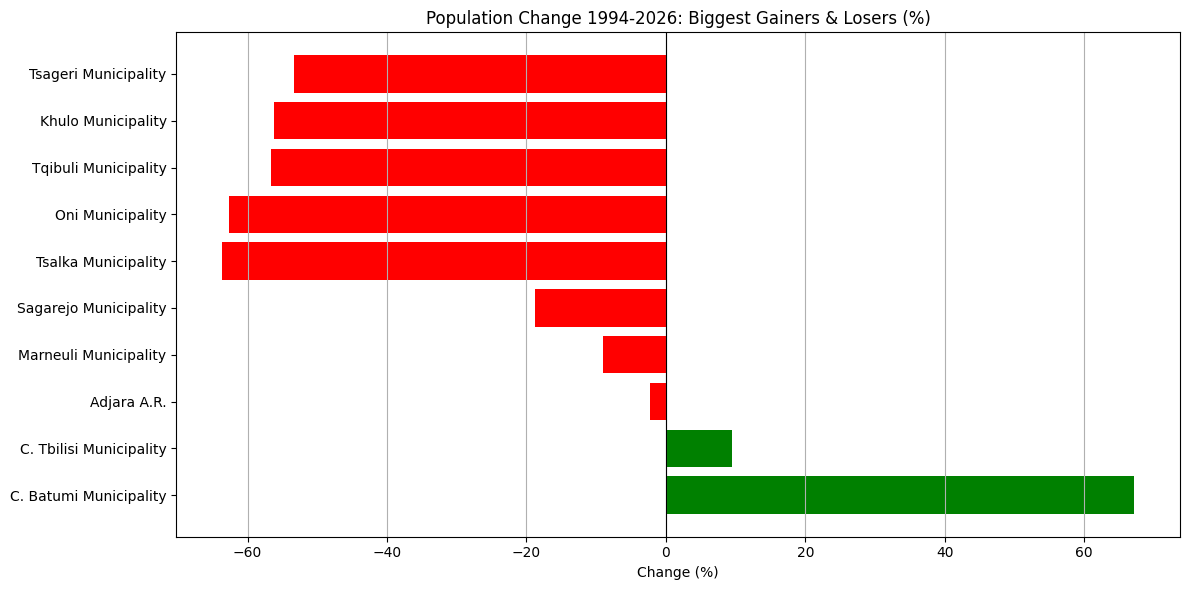

In [13]:
# Combine top growing and declining for visualization
top_growing = regions_only.nlargest(5, 'change_pct')
top_declining = regions_only.nsmallest(5, 'change_pct')
combined = pd.concat([top_growing, top_declining])

plt.figure(figsize=(12, 6))
colors = ['green' if x > 0 else 'red' for x in combined['change_pct']]
plt.barh(combined['regions, self-governed units'], combined['change_pct'], color=colors)
plt.title('Population Change 1994-2026: Biggest Gainers & Losers (%)')
plt.xlabel('Change (%)')
plt.axvline(0, color='black', linewidth=0.8)
plt.grid(True, axis='x')
plt.tight_layout()
plt.show()